# ShopNow: árboles de decisión para anticipar cancelaciones

Proyecto de la secuencia **Minería de datos** (Base de Datos Aplicada).

La pregunta que organiza todo el trabajo es:

**¿Podemos aprender reglas a partir de los pedidos históricos para predecir si un pedido nuevo será cancelado?**

## Cómo ejecutar este notebook

1. Instalá las dependencias desde la carpeta del proyecto: `pip install -r requirements.txt`
2. Abrí esta carpeta como directorio de trabajo.
3. Ejecutá las celdas en orden. Cada bloque está pensado para proyectarse y comentarse antes de pasar al siguiente.

## Qué vas a recorrer

| Parte | Qué se construye |
| --- | --- |
| 1 | El problema, la tabla y la variable objetivo |
| 2 | Por qué Gini, por qué se habla de bits, y la primera división |
| 3 | El árbol a mano, las reglas y los errores |
| 4 | Entrenamiento con scikit-learn y visualización |
| 5 | Entrenamiento frente a prueba, métricas y sobreajuste |
| 6 | Un pedido nuevo y la decisión empresarial |

## Parte 1. El problema y los datos

ShopNow registra un crecimiento de las cancelaciones. La gerencia quiere intervenir **antes** de que el pedido se cancele. Para eso dispone de 16 pedidos históricos con cuatro características y el resultado ya conocido.

Esta tarea es de **aprendizaje supervisado**: cada ejemplo trae las características y la respuesta. El algoritmo no descubre grupos por su cuenta, sino que aprende a imitar una etiqueta que ya existe.

| Concepto | En ShopNow |
| --- | --- |
| Aprendizaje supervisado | Hay ejemplos históricos con el resultado conocido |
| Variable objetivo | `Canceló`: la clase que se quiere predecir |
| Atributos predictivos | Cliente nuevo, forma de pago, demora y descuento alto |
| Clasificación | La respuesta es una categoría (canceló o no canceló), no un número continuo |

La respuesta correcta está en la columna `Canceló`, y el modelo tiene que aprender a anticiparla en pedidos que todavía no ocurrieron.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

def ubicar_datos():
    nombre = Path("datos") / "pedidos_shopnow.csv"
    if nombre.exists():
        return nombre
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidato = base / "datos" / "pedidos_shopnow.csv"
        if candidato.exists():
            return candidato
    raise FileNotFoundError(
        "No se encontró datos/pedidos_shopnow.csv. "
        "Abrí el notebook desde la carpeta del proyecto."
    )

tabla = pd.read_csv(ubicar_datos(), encoding="utf-8")
tabla

,Pedido,Cliente nuevo,Pago,Demora,Descuento alto,Canceló
0,P01,Sí,Transferencia,Sí,Sí,Sí
1,P02,Sí,Tarjeta,Sí,No,Sí
2,P03,Sí,Transferencia,Sí,No,Sí
3,P04,No,Transferencia,Sí,Sí,Sí
4,P05,No,Tarjeta,Sí,No,No
5,P06,No,Tarjeta,Sí,Sí,Sí
6,P07,Sí,Tarjeta,No,Sí,No
7,P08,Sí,Transferencia,No,No,No
8,P09,No,Transferencia,No,Sí,No
9,P10,No,Tarjeta,No,No,No


Cada fila es un pedido. `Canceló` es la **variable objetivo**. Las otras columnas, salvo el identificador `Pedido`, son los **atributos predictivos**.

El algoritmo no lee «Sí» ni «Transferencia». Necesita números. Como todas las variables son categorías de dos valores, se codifican con 0 y 1.

In [3]:
# Bloque 1. Misma tabla, ahora en ceros y unos.
datos = pd.DataFrame(
    {
        "pedido": tabla["Pedido"],
        "cliente_nuevo": tabla["Cliente nuevo"].map({"No": 0, "Sí": 1}),
        "pago_transferencia": tabla["Pago"].map({"Tarjeta": 0, "Transferencia": 1}),
        "demora": tabla["Demora"].map({"No": 0, "Sí": 1}),
        "descuento_alto": tabla["Descuento alto"].map({"No": 0, "Sí": 1}),
        "cancelo": tabla["Canceló"].map({"No": 0, "Sí": 1}),
    }
)

print("Codificación usada:")
print("  cliente_nuevo:        No = 0, Sí = 1")
print("  pago_transferencia:   Tarjeta = 0, Transferencia = 1")
print("  demora:               No = 0, Sí = 1")
print("  descuento_alto:       No = 0, Sí = 1")
print("  cancelo:              No = 0, Sí = 1")
datos

Codificación usada:
  cliente_nuevo:        No = 0, Sí = 1
  pago_transferencia:   Tarjeta = 0, Transferencia = 1
  demora:               No = 0, Sí = 1
  descuento_alto:       No = 0, Sí = 1
  cancelo:              No = 0, Sí = 1


,pedido,cliente_nuevo,pago_transferencia,demora,descuento_alto,cancelo
0,P01,1,1,1,1,1
1,P02,1,0,1,0,1
2,P03,1,1,1,0,1
3,P04,0,1,1,1,1
4,P05,0,0,1,0,0
5,P06,0,0,1,1,1
6,P07,1,0,0,1,0
7,P08,1,1,0,0,0
8,P09,0,1,0,1,0
9,P10,0,0,0,0,0


## Parte 2. Cómo elige el algoritmo la primera pregunta

Si hubiera que separar los pedidos a mano, se podría empezar por la demora, por el pago, por el descuento o por el tipo de cliente. La intuición puede acertar, pero el árbol necesita un **número** para comparar las cuatro preguntas y quedarse con la que deja los grupos más puros.

Un nodo es **puro** cuando todos sus pedidos son de una sola clase: ahí ya se puede predecir. Si hay cancelaciones y pedidos cumplidos mezclados, el nodo es **impuro** y la predicción se equivoca más.

### Por qué la impureza de Gini

El árbol de este cuaderno usa la **impureza de Gini** (`criterion="gini"`). Se elige porque resume la mezcla en una sola cuenta, fácil de hacer:

- **0** significa nodo puro;
- con dos clases, **0,5** es el peor caso: mitad cancela y mitad no.

La idea concreta: si sacás dos pedidos al azar del mismo nodo, Gini es la probabilidad de que **no sean de la misma clase**.

$$
\text{Gini} = 1 - \left(p_{\text{cancela}}^{2} + p_{\text{no cancela}}^{2}\right)
$$

$p^{2}$ es la chance de sacar dos pedidos iguales. Lo que sobra es la mezcla.

En los 16 pedidos hay 8 cancelaciones y 8 cumplidos, así que cada clase vale 0,5:

$$
\text{Gini} = 1 - \left(0{,}5^{2} + 0{,}5^{2}\right) = 0{,}5
$$

Ese 0,5 es el punto de partida, antes de preguntar nada. Una buena primera pregunta es la que **más lo baje**.

Más abajo aparece otra medida, la entropía, que dice lo mismo en **bits**. Primero cerramos Gini, que es la que va a usar el árbol.

In [4]:
# Bloque 2. Separar atributos y objetivo.
columnas_x = ["cliente_nuevo", "pago_transferencia", "demora", "descuento_alto"]
X = datos[columnas_x]
y = datos["cancelo"]

print("Cantidad de registros:", len(datos))
print("Cantidad de variables predictoras:", X.shape[1])
print("Cancelaciones:", int(y.sum()))
print("Pedidos no cancelados:", int((y == 0).sum()))


def gini(clases):
    # Impureza de Gini. 0 = nodo puro. 0.5 = empate entre las dos clases.
    clases = np.asarray(clases)
    if len(clases) == 0:
        return 0.0
    p_cancela = clases.mean()
    p_no = 1 - p_cancela
    return 1 - (p_cancela**2 + p_no**2)


def entropia(clases):
    # Incertidumbre del nodo, en bits.
    # 0 = ya se sabe la clase. 1 = empate total entre las dos clases.
    clases = np.asarray(clases)
    if len(clases) == 0:
        return 0.0
    p_cancela = clases.mean()
    total = 0.0
    for p in (p_cancela, 1 - p_cancela):
        if p > 0:
            total -= p * np.log2(p)
    return total


gini_raiz = gini(y)
entropia_raiz = entropia(y)
print()
print(f"Gini del conjunto completo = {gini_raiz:.2f}")
print(f"Entropía del conjunto completo = {entropia_raiz:.2f} bits")

Cantidad de registros: 16
Cantidad de variables predictoras: 4
Cancelaciones: 8
Pedidos no cancelados: 8

Gini del conjunto completo = 0.50
Entropía del conjunto completo = 1.00 bits


In [5]:
def evaluar_division(columna):
    # Promedio ponderado de cada rama.
    # reduccion_gini: cuánto baja la mezcla.
    # ganancia_informacion: cuántos bits de incertidumbre se ahorran.
    gini_ponderado = 0.0
    entropia_ponderada = 0.0
    detalle = []
    for valor, grupo in datos.groupby(columna):
        peso = len(grupo) / len(datos)
        gini_grupo = gini(grupo["cancelo"])
        entropia_grupo = entropia(grupo["cancelo"])
        gini_ponderado += peso * gini_grupo
        entropia_ponderada += peso * entropia_grupo
        detalle.append(
            {
                "atributo": columna,
                "valor": int(valor),
                "pedidos": len(grupo),
                "cancelaciones": int(grupo["cancelo"].sum()),
                "no_cancelados": int((grupo["cancelo"] == 0).sum()),
                "gini": round(gini_grupo, 4),
            }
        )
    return detalle, gini_ponderado, entropia_ponderada


filas = []
detalles = {}
for columna in columnas_x:
    detalle, gini_division, entropia_division = evaluar_division(columna)
    detalles[columna] = detalle
    filas.append(
        {
            "atributo": columna,
            "gini_division": round(gini_division, 4),
            "reduccion_gini": round(gini_raiz - gini_division, 4),
            "ganancia_informacion": round(entropia(y) - entropia_division, 4),
        }
    )

comparacion = pd.DataFrame(filas).sort_values("reduccion_gini", ascending=False)
comparacion

,atributo,gini_division,reduccion_gini,ganancia_informacion
2,demora,0.2000,0.3000,0.5488
0,cliente_nuevo,0.4688,0.0312,0.0456
1,pago_transferencia,0.4688,0.0312,0.0456
3,descuento_alto,0.4688,0.0312,0.0456


La tabla responde «¿por cuál atributo empezar?». **Demora** es la pregunta que más ordena el conjunto. Las otras tres apenas separan las clases: cada una baja el Gini solo 0,0312.

### Cómo se lee el cálculo de la demora

- Con demora: 10 pedidos, 8 cancelaciones y 2 no cancelados. Gini = 0,32. Sigue mezclado, pero menos que 0,50.
- Sin demora: 6 pedidos, todos cumplidos. Gini = 0. Ese grupo ya se puede cerrar.

No alcanza con mirar cada rama sola. Una rama chica y pura no debería pesar igual que una rama grande. Por eso el Gini de la división es un **promedio ponderado** por la cantidad de pedidos:

$$
\text{Gini}_{\text{división}} = \frac{10}{16}(0{,}32) + \frac{6}{16}(0) = 0{,}2
$$

$$
\text{Reducción de Gini} = 0{,}5 - 0{,}2 = 0{,}3
$$

El algoritmo se queda con la pregunta de **mayor reducción**. En este nodo, demora gana por lejos. La elección es **local**: mira solo el nodo de ahora. Una buena primera pregunta no garantiza, por sí sola, el mejor árbol completo.

### Por qué la otra columna habla de bits

`ganancia_informacion` mide la misma mezcla con otra fórmula: la **entropía**. No cambia el objetivo. Cambia la unidad.

Un **bit** es la respuesta a una pregunta de sí o no. Es la unidad con la que se mide la información: la misma idea de guardar un 0 o un 1.

- Grupo **mitad y mitad** (8 y 8): estás tan a ciegas como con una moneda. Todavía te hace falta preguntar «¿cancela?». Eso es **1 bit** de incertidumbre.
- Grupo **puro**: ya sabés la clase. Incertidumbre = **0 bits**.
- Grupo **desparejo**: queda un valor entre 0 y 1.

La fórmula usa logaritmo en base 2 para que el resultado salga en bits:

$$
\text{Entropía} = -\left(p_{\text{cancela}}\log_2 p_{\text{cancela}} + p_{\text{no cancela}}\log_2 p_{\text{no cancela}}\right)
$$

En la raíz, $\log_2(0{,}5) = -1$, y la cuenta da exactamente **1 bit**. Por eso la celda anterior imprime `Entropía del conjunto completo = 1.00 bits`.

La **ganancia de información** es la incertidumbre que te ahorrás al preguntar: entropía de antes menos el promedio de las ramas. Demora ahorra cerca de **0,55 bits**. Las otras preguntas ahorran menos de **0,05**.

### Por qué mostramos las dos medidas

| | Gini | Entropía |
| --- | --- | --- |
| Qué premia | Que las ramas queden puras | Que baje la incertidumbre |
| Escala en este problema | de 0 a 0,5 | de 0 a 1 bit |
| Dónde aparece | Criterio por defecto de scikit-learn | Criterio clásico de los árboles ID3 y C4.5 |

En ShopNow las dos eligen **demora**. Eso pasa seguido, pero no siempre. En el resto del cuaderno el árbol se entrena con Gini, porque es el número que vas a leer en cada nodo del gráfico.

In [6]:
print("Detalle de la división por demora")
for grupo in detalles["demora"]:
    etiqueta = "con demora" if grupo["valor"] == 1 else "sin demora"
    print(
        f"  {etiqueta}: {grupo['pedidos']} pedidos, "
        f"{grupo['cancelaciones']} cancelaciones, "
        f"{grupo['no_cancelados']} no cancelados, "
        f"Gini = {grupo['gini']:.2f}"
    )

print()
print("Gini división = (10/16)*(0.32) + (6/16)*(0) = 0.20")
print("Reducción de impureza = 0.50 - 0.20 = 0.30")

Detalle de la división por demora
  sin demora: 6 pedidos, 0 cancelaciones, 6 no cancelados, Gini = 0.00
  con demora: 10 pedidos, 8 cancelaciones, 2 no cancelados, Gini = 0.32

Gini división = (10/16)*(0.32) + (6/16)*(0) = 0.20
Reducción de impureza = 0.50 - 0.20 = 0.30


## Parte 3. El árbol, las reglas y los errores

Con la primera pregunta ya se puede dibujar el árbol.

- **Nodo raíz:** la primera división. Aquí es `demora`.
- **Rama:** el resultado de una condición. «Sin demora» es una rama; «con demora» es la otra.
- **Hoja:** el extremo del árbol, donde se predice una clase.
- **Nodo interno:** una decisión intermedia, entre la raíz y las hojas.

La rama **sin demora** ya es pura: los 6 pedidos se cumplieron. Esa rama puede cerrarse en una hoja que predice «No cancela».

La rama **con demora** sigue mezclada (8 cancelaciones y 2 pedidos cumplidos). Hay que hacer otra pregunta dentro de ese grupo. La hoja, cuando finalmente se cierra, predice la **clase mayoritaria** del grupo. Puede contener pedidos de las dos clases: la predicción no es una certeza.

In [7]:
# Segunda división: solo dentro de los pedidos con demora.
con_demora = datos[datos["demora"] == 1].copy()
gini_demora = gini(con_demora["cancelo"])
print(
    f"Pedidos con demora: {len(con_demora)} | "
    f"Gini del nodo = {gini_demora:.2f}"
)

candidatas = ["cliente_nuevo", "pago_transferencia", "descuento_alto"]
filas_segunda = []
for columna in candidatas:
    gini_ponderado = 0.0
    for valor, grupo in con_demora.groupby(columna):
        gini_ponderado += (len(grupo) / len(con_demora)) * gini(grupo["cancelo"])
        print(
            f"  {columna} = {int(valor)}: n = {len(grupo)}, "
            f"canceló = {int(grupo['cancelo'].sum())}, "
            f"Gini = {gini(grupo['cancelo']):.2f}"
        )
    filas_segunda.append(
        {
            "atributo": columna,
            "gini_division": round(gini_ponderado, 4),
            "reduccion_gini": round(gini_demora - gini_ponderado, 4),
        }
    )
    print()

pd.DataFrame(filas_segunda).sort_values("reduccion_gini", ascending=False)

Pedidos con demora: 10 | Gini del nodo = 0.32
  cliente_nuevo = 0: n = 4, canceló = 3, Gini = 0.38
  cliente_nuevo = 1: n = 6, canceló = 5, Gini = 0.28

  pago_transferencia = 0: n = 5, canceló = 3, Gini = 0.48
  pago_transferencia = 1: n = 5, canceló = 5, Gini = 0.00

  descuento_alto = 0: n = 5, canceló = 3, Gini = 0.48
  descuento_alto = 1: n = 5, canceló = 5, Gini = 0.00



,atributo,gini_division,reduccion_gini
1,pago_transferencia,0.2400,0.0800
2,descuento_alto,0.2400,0.0800
0,cliente_nuevo,0.3167,0.0033


Dentro de los pedidos con demora, **pago** y **descuento alto** bajan el Gini en la misma cantidad (0,08). Las dos preguntas dejan un grupo puro de 5 cancelaciones y otro grupo de 5 pedidos todavía mezclado (3 cancelaciones y 2 cumplidos). El tipo de cliente casi no ayuda: su reducción es mucho más chica.

Cuando la reducción es la misma, las dos preguntas ordenan **igual de bien** según la medida. No hay un ganador estadístico. Scikit-learn desempata solo y la semilla `random_state` fija ese desempate para que el árbol se pueda repetir en clase.

### Regla de la primera división, y sus errores

Si el árbol se detuviera en la demora, la regla sería:

- si no hay demora, predecir «No cancela»;
- si hay demora, predecir «Cancela», porque 8 de esos 10 pedidos se cancelaron.

La hoja predice la **clase mayoritaria**: la que más veces aparece en ese grupo. No es una certeza. Por eso esta regla acierta los 6 pedidos sin demora y las 8 cancelaciones con demora, pero falla en **P05** y **P11**: tienen demora, el modelo anuncia cancelación y el pedido se cumple.

Esos dos casos son **falsos positivos**: el modelo predice cancelación y el pedido no se cancela. Un **falso negativo** es el caso inverso: el modelo dice que el pedido se cumple y después se cancela.

Para ShopNow no cuestan lo mismo.

- Un falso positivo puede disparar un llamado o un descuento de más.
- Un falso negativo deja pasar una cancelación que la empresa quería evitar.

Si ese segundo costo es el más alto, mirar solo el porcentaje total de aciertos se queda corto. Por eso, más adelante, además del accuracy se miran precision y recall.

In [8]:
predicho_por_demora = datos["demora"]
revision = datos[["pedido", "demora", "cancelo"]].copy()
revision["predicho"] = predicho_por_demora.map({0: "No cancela", 1: "Cancela"})
revision["real"] = revision["cancelo"].map({0: "No cancela", 1: "Cancela"})
revision["resultado"] = np.where(
    predicho_por_demora == revision["cancelo"],
    "acierto",
    np.where(predicho_por_demora == 1, "falso positivo", "falso negativo"),
)
print("Aciertos de la regla 'si hay demora, predecir cancelación':")
print(f"  {(predicho_por_demora == y).sum()} de {len(y)}")
revision.loc[revision["resultado"] != "acierto", ["pedido", "real", "predicho", "resultado"]]

Aciertos de la regla 'si hay demora, predecir cancelación':
  14 de 16


,pedido,real,predicho,resultado
4,P05,No cancela,Cancela,falso positivo
10,P11,No cancela,Cancela,falso positivo


P02 y P11 muestran además un límite de los datos, no solo del árbol. Los dos son clientes nuevos, pagan con tarjeta, tienen demora y no tienen descuento alto. **Las características son idénticas y la etiqueta no:** P02 se cancela y P11 no. Ninguna regla construida con estas columnas puede clasificar bien los dos al mismo tiempo.

El procedimiento que el algoritmo repite es:

1. Partir de registros históricos etiquetados.
2. Evaluar atributos y divisiones candidatas.
3. Elegir la división que más reduce la impureza.
4. Repetir hasta una condición de parada: nodo puro, sin atributos útiles o un tope de profundidad.
5. Usar el árbol para predecir casos nuevos.

Si el árbol sigue creciendo hasta memorizar los 16 pedidos, las reglas pueden describir este histórico y fallar en el pedido que llegue mañana. Eso es el **sobreajuste**, y es el eje de la implementación.

## Parte 4. El mismo caso en Python

`pandas` ordena la tabla y `scikit-learn` entrena el árbol.

Primero se ajusta un árbol con **los 16 pedidos**. Ese árbol sirve para leer las reglas. No sirve para afirmar que el modelo va a funcionar con pedidos futuros, porque se evalúa con los mismos registros que usó para aprender.

|--- demora <= 0.50
|   |--- class: 0
|--- demora >  0.50
|   |--- descuento_alto <= 0.50
|   |   |--- pago_transferencia <= 0.50
|   |   |   |--- cliente_nuevo <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- cliente_nuevo >  0.50
|   |   |   |   |--- class: 0
|   |   |--- pago_transferencia >  0.50
|   |   |   |--- class: 1
|   |--- descuento_alto >  0.50
|   |   |--- class: 1

Profundidad: 4
Hojas: 5
Aciertos sobre los mismos 16 pedidos: 0.9375


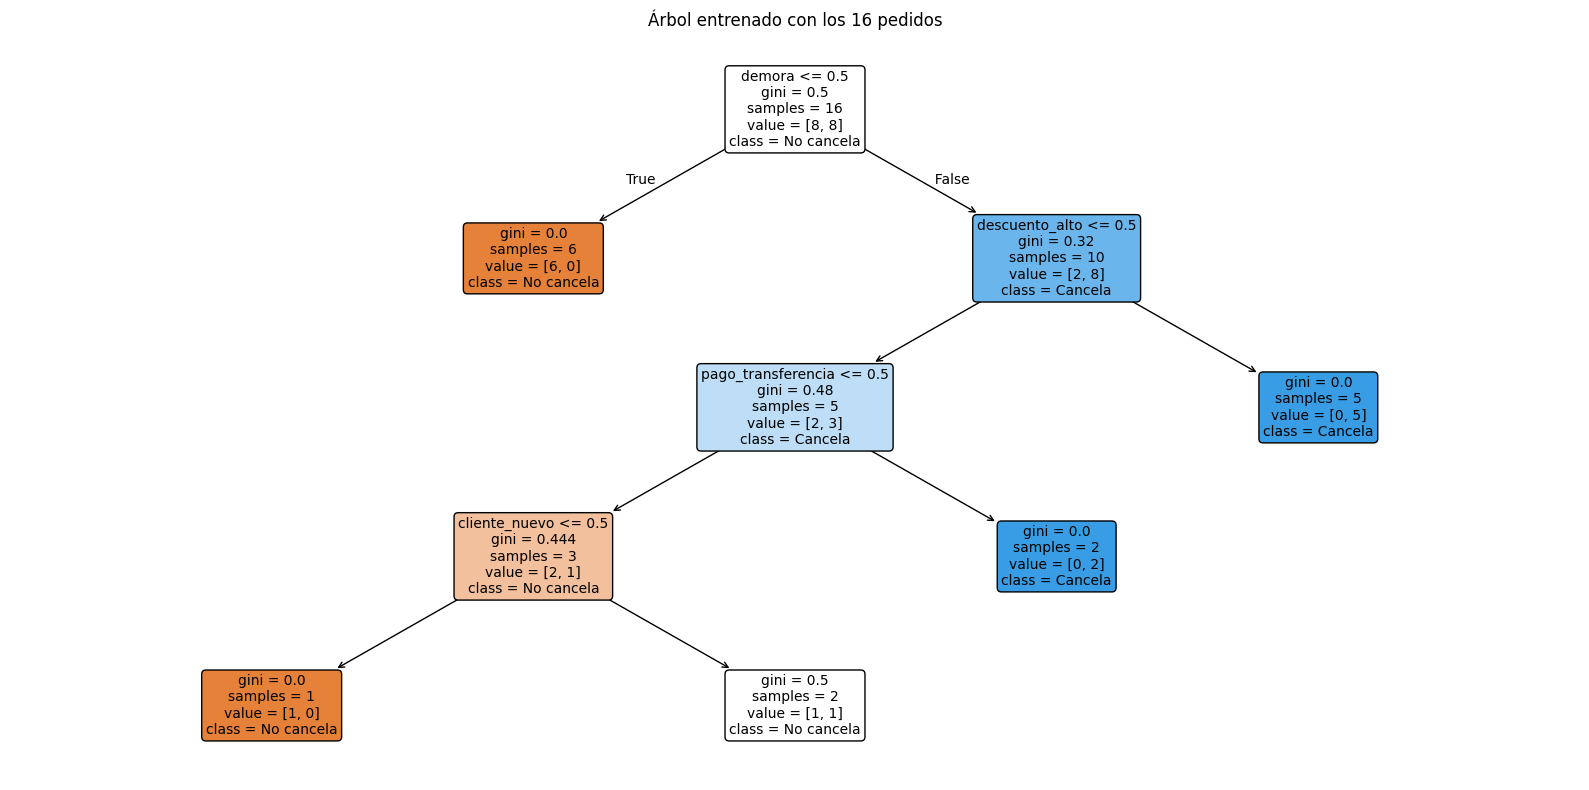

In [9]:
# Árbol ilustrativo con los 16 pedidos, para compararlo con el pizarrón.
arbol_completo = DecisionTreeClassifier(criterion="gini", max_depth=None, random_state=42)
arbol_completo.fit(X, y)

print(export_text(arbol_completo, feature_names=columnas_x, decimals=2))
print("Profundidad:", arbol_completo.get_depth())
print("Hojas:", arbol_completo.get_n_leaves())
print(
    "Aciertos sobre los mismos 16 pedidos:",
    f"{arbol_completo.score(X, y):.4f}",
)

Path("figuras").mkdir(exist_ok=True)
plt.figure(figsize=(16, 8))
plot_tree(
    arbol_completo,
    feature_names=columnas_x,
    class_names=["No cancela", "Cancela"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title("Árbol entrenado con los 16 pedidos")
plt.tight_layout()
plt.savefig(Path("figuras") / "arbol_completo.png", dpi=150, bbox_inches="tight")
plt.show()

Lectura del gráfico. Cada caja repite las cuentas de la parte 2:

- `gini`: la misma impureza de antes. 0 es un grupo puro. Con dos clases, 0,5 es un empate.
- `samples`: cuántos pedidos de entrenamiento llegan ahí.
- `value`: cantidad de cada clase, en el orden [No cancela, Cancela].
- `class`: la clase que predice esa hoja, es decir la mayoritaria. Si hay empate, scikit-learn se queda con la primera clase del vector (`No cancela`).

La raíz vuelve a ser la demora, la pregunta que más bajaba el Gini. La rama sin demora predice «No cancela». En la rama con demora el algoritmo pregunta por el descuento y después por el pago. `max_depth=None` no arma un árbol infinito: crece hasta que se cumple una condición de parada (nodo puro, o ya no queda una pregunta que separe mejor).

El acierto de 0,9375 (15 de 16) es el techo de estas columnas. El pedido que queda mal es el que comparte características con otro de etiqueta distinta. Memorizar más no lo resuelve.

## Parte 5. Entrenamiento, prueba y sobreajuste

Para estimar cómo se comportaría el árbol con pedidos que no vio, hay que separar los registros **antes** de ajustarlo.

- El conjunto de **entrenamiento** es el que el árbol usa para elegir las preguntas.
- El conjunto de **prueba** se reserva. El modelo no lo mira mientras crece.

Con 16 pedidos, `test_size=0.25` deja 12 para aprender y 4 para evaluar. `stratify=y` mantiene, en cada parte, la misma proporción de cancelaciones. `random_state=42` hace que la partición sea la misma cada vez que se corre la clase.

Cuatro pedidos de prueba son muy pocos: cada uno pesa el 25 % de la evaluación. El ejercicio enseña el procedimiento. No alcanza para decidir si el modelo serviría en producción.

In [9]:
# Bloque 3. Separar entrenamiento y prueba antes de ajustar el modelo.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))
print("Cancelaciones en entrenamiento:", int(y_train.sum()), "de", len(y_train))
print("Cancelaciones en prueba:", int(y_test.sum()), "de", len(y_test))
print()
print("Pedidos de entrenamiento:", ", ".join(datos.loc[X_train.index, "pedido"]))
print("Pedidos de prueba:", ", ".join(datos.loc[X_test.index, "pedido"]))

Registros de entrenamiento: 12
Registros de prueba: 4
Cancelaciones en entrenamiento: 6 de 12
Cancelaciones en prueba: 2 de 4

Pedidos de entrenamiento: P12, P06, P07, P01, P04, P16, P11, P08, P10, P05, P03, P15
Pedidos de prueba: P09, P02, P14, P13


|--- demora <= 0.50
|   |--- class: 0
|--- demora >  0.50
|   |--- descuento_alto <= 0.50
|   |   |--- pago_transferencia <= 0.50
|   |   |   |--- class: 0
|   |   |--- pago_transferencia >  0.50
|   |   |   |--- class: 1
|   |--- descuento_alto >  0.50
|   |   |--- class: 1

Profundidad: 3
Hojas: 4


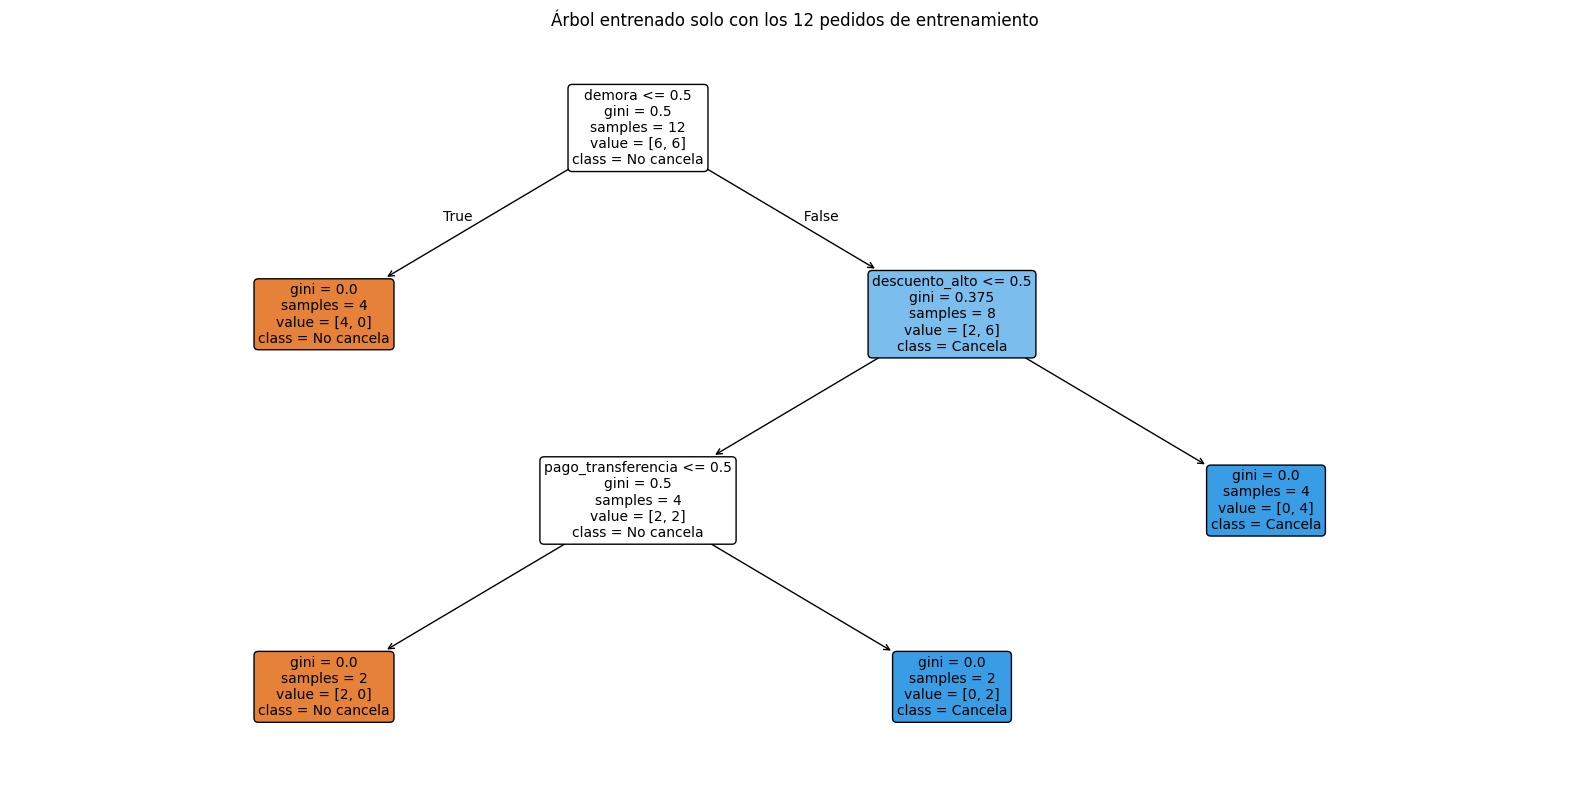

In [10]:
# Bloque 4. Entrenar el árbol solo con los pedidos de entrenamiento.
modelo = DecisionTreeClassifier(
    criterion="gini",
    max_depth=None,
    random_state=42,
)
modelo.fit(X_train, y_train)

print(export_text(modelo, feature_names=columnas_x, decimals=2))
print("Profundidad:", modelo.get_depth())
print("Hojas:", modelo.get_n_leaves())

plt.figure(figsize=(16, 8))
plot_tree(
    modelo,
    feature_names=columnas_x,
    class_names=["No cancela", "Cancela"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title("Árbol entrenado solo con los 12 pedidos de entrenamiento")
plt.tight_layout()
plt.savefig(Path("figuras") / "arbol_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

Este árbol puede diferir del dibujo hecho con los 16 pedidos, porque ahora aprende con 12. Con esta semilla la raíz sigue siendo la demora y las preguntas siguientes son el descuento y el pago. Las hojas de entrenamiento quedan puras: el árbol acierta los 12 pedidos con los que aprendió.

Traducción de esas reglas:

- sin demora → **No cancela**;
- con demora y descuento alto → **Cancela**;
- con demora, sin descuento alto y pago por transferencia → **Cancela**;
- con demora, sin descuento alto y pago con tarjeta → **No cancela**.

Matriz de confusión:
[[2 0]
 [1 1]]

Accuracy: 0.75

              precision    recall  f1-score   support

  No cancela       0.67      1.00      0.80         2
     Cancela       1.00      0.50      0.67         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



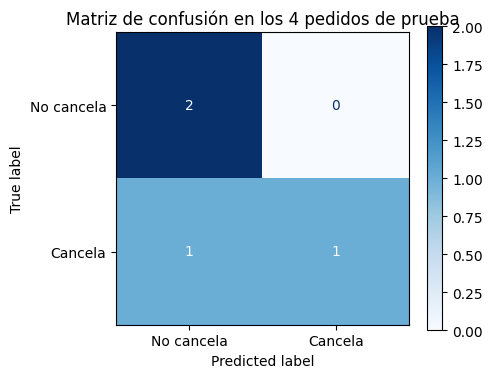

In [11]:
# Bloque 5. Evaluar con los pedidos que el árbol no usó para crecer.
predicciones = modelo.predict(X_test)

print("Matriz de confusión:")
print(confusion_matrix(y_test, predicciones))
print()
print("Accuracy:", accuracy_score(y_test, predicciones))
print()
print(
    classification_report(
        y_test,
        predicciones,
        labels=[0, 1],
        target_names=["No cancela", "Cancela"],
        zero_division=0,
    )
)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones,
    display_labels=["No cancela", "Cancela"],
    cmap="Blues",
    ax=ax,
)
ax.set_title("Matriz de confusión en los 4 pedidos de prueba")
plt.tight_layout()
plt.savefig(Path("figuras") / "matriz_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

La matriz se lee así: las **filas** son la clase real y las **columnas**, la clase que predijo el árbol.

|  | Predice «No cancela» | Predice «Cancela» |
| --- | --- | --- |
| Real «No cancela» | Verdadero negativo: acertó un pedido cumplido | Falso positivo: avisó de más |
| Real «Cancela» | Falso negativo: se le escapó una cancelación | Verdadero positivo: avisó a tiempo |

Con esta partición la matriz es `[[2, 0], [1, 1]]`:

- 2 pedidos cumplidos, bien anticipados;
- 0 falsos positivos;
- 1 falso negativo: una cancelación que el modelo no avisó;
- 1 cancelación bien detectada.

### Por qué no alcanza con un solo porcentaje

El **accuracy** es la proporción de pedidos bien clasificados. Acá es 0,75: 3 de 4. Es fácil de contar, pero trata igual un aviso de más y una cancelación que se escapa. En ShopNow esos errores no cuestan lo mismo, así que se agregan dos medidas solo sobre la clase «Cancela»:

- **Precision:** de las veces que el modelo gritó «va a cancelar», ¿cuántas tenía razón? Acá es 1,00: la única alerta era correcta. Si fuera baja, ShopNow molestaría a clientes que iban a cumplir el pedido.
- **Recall** (sensibilidad): de las cancelaciones que de verdad ocurrieron, ¿cuántas vio el modelo? Acá es 0,50: detectó 1 de 2. Si es bajo, se le escapan justo los casos que la gerencia quería anticipar.

Por eso, si a ShopNow le duele más no enterarse de una cancelación, la medida que hay que mirar es el recall, no solo el accuracy. Un porcentaje alto de aciertos puede convivir con varias cancelaciones invisibles para el modelo.

In [12]:
detalle_prueba = X_test.copy()
detalle_prueba.insert(0, "pedido", datos.loc[X_test.index, "pedido"])
detalle_prueba["real"] = y_test.map({0: "No cancela", 1: "Cancela"})
detalle_prueba["predicho"] = pd.Series(predicciones, index=X_test.index).map(
    {0: "No cancela", 1: "Cancela"}
)
detalle_prueba["acierto"] = np.where(
    predicciones == y_test.to_numpy(),
    "sí",
    "no",
)
detalle_prueba

,pedido,cliente_nuevo,pago_transferencia,demora,descuento_alto,real,predicho,acierto
8,P09,0,1,0,1,No cancela,No cancela,sí
1,P02,1,0,1,0,Cancela,No cancela,no
13,P14,0,0,0,1,No cancela,No cancela,sí
12,P13,1,1,1,1,Cancela,Cancela,sí


El error de prueba es **P02**. Comparte características con **P11**, que sí está en el entrenamiento y no se canceló. El árbol aprendió, con P11, la regla «tarjeta, con demora y sin descuento alto → no cancela» y se la aplicó a P02, que sí se canceló. Es un falso negativo.

### Un árbol de una sola pregunta frente a un árbol sin tope

`max_depth` limita cuántas preguntas puede encadenar el árbol. También existe la **poda**, que deja crecer el árbol y después corta ramas que no mejoran la generalización. En esta clase alcanza con comparar dos topes:

- árbol simple: `max_depth=1`, solo la primera pregunta;
- árbol complejo: `max_depth=None`, crece hasta la condición de parada.

In [13]:
# Bloque 6. Misma partición, dos complejidades.
modelos = {
    "Árbol simple": DecisionTreeClassifier(criterion="gini", max_depth=1, random_state=42),
    "Árbol complejo": DecisionTreeClassifier(criterion="gini", max_depth=None, random_state=42),
}

filas_comparacion = []
for nombre, arbol in modelos.items():
    arbol.fit(X_train, y_train)
    filas_comparacion.append(
        {
            "modelo": nombre,
            "profundidad": arbol.get_depth(),
            "hojas": arbol.get_n_leaves(),
            "accuracy_entrenamiento": round(arbol.score(X_train, y_train), 4),
            "accuracy_prueba": round(arbol.score(X_test, y_test), 4),
        }
    )
    print(nombre)
    print("  Profundidad:", arbol.get_depth())
    print("  Hojas:", arbol.get_n_leaves())
    print("  Accuracy entrenamiento:", round(arbol.score(X_train, y_train), 4))
    print("  Accuracy prueba:", round(arbol.score(X_test, y_test), 4))
    print()

pd.DataFrame(filas_comparacion)

Árbol simple
  Profundidad: 1
  Hojas: 2
  Accuracy entrenamiento: 0.8333
  Accuracy prueba: 1.0

Árbol complejo
  Profundidad: 3
  Hojas: 4
  Accuracy entrenamiento: 1.0
  Accuracy prueba: 0.75



,modelo,profundidad,hojas,accuracy_entrenamiento,accuracy_prueba
0,Árbol simple,1,2,0.8333,1.00
1,Árbol complejo,3,4,1.0000,0.75


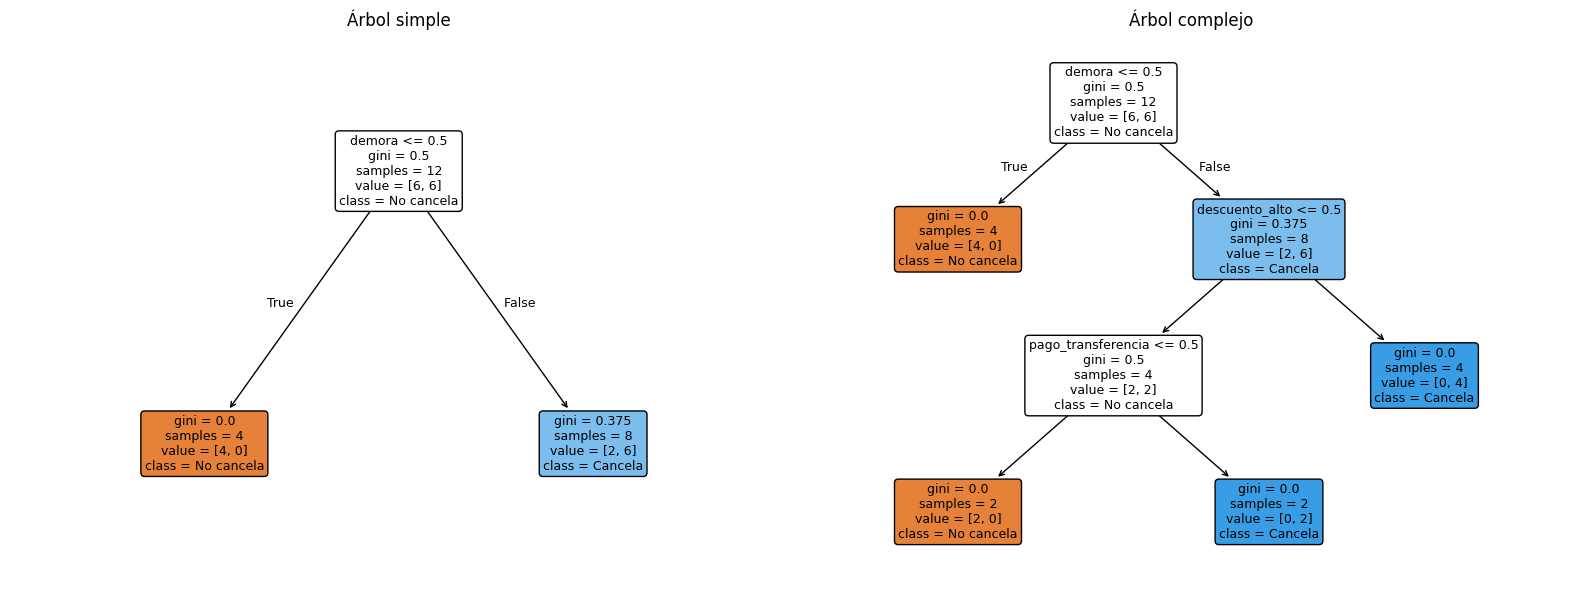

In [14]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
for eje, (nombre, arbol) in zip(ejes, modelos.items()):
    plot_tree(
        arbol,
        feature_names=columnas_x,
        class_names=["No cancela", "Cancela"],
        filled=True,
        rounded=True,
        fontsize=9,
        ax=eje,
    )
    eje.set_title(nombre)

plt.tight_layout()
plt.savefig(Path("figuras") / "arboles_simple_y_complejo.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
# El mismo pedido de prueba, leído por los dos árboles.
lado_a_lado = pd.DataFrame(
    {
        "pedido": datos.loc[X_test.index, "pedido"],
        "real": y_test.map({0: "No cancela", 1: "Cancela"}),
        "pred_simple": pd.Series(
            modelos["Árbol simple"].predict(X_test), index=X_test.index
        ).map({0: "No cancela", 1: "Cancela"}),
        "pred_complejo": pd.Series(
            modelos["Árbol complejo"].predict(X_test), index=X_test.index
        ).map({0: "No cancela", 1: "Cancela"}),
    }
)
lado_a_lado

,pedido,real,pred_simple,pred_complejo
8,P09,No cancela,No cancela,No cancela
1,P02,Cancela,Cancela,No cancela
13,P14,No cancela,No cancela,No cancela
12,P13,Cancela,Cancela,Cancela


Con `random_state=42` el resultado de la comparación es:

| Modelo | Profundidad | Hojas | Accuracy entrenamiento | Accuracy prueba |
| --- | --- | --- | --- | --- |
| Árbol simple | 1 | 2 | 0,8333 (10 de 12) | 1,00 (4 de 4) |
| Árbol complejo | 3 | 4 | 1,00 (12 de 12) | 0,75 (3 de 4) |

El árbol complejo acierta **todo** el entrenamiento y empeora en la prueba. El simple se equivoca en dos pedidos de entrenamiento (los cumplidos que tenían demora) y, en esta partición chica, acierta los cuatro de prueba. Entre ellos está P02: el árbol simple lo clasifica como cancelación solo porque tiene demora, y esa predicción coincide con lo que ocurrió.

La pregunta de la clase es: ¿qué modelo elegirían si el complejo acierta más en entrenamiento, pero no mejora en prueba?

La respuesta que se busca es esta: el árbol complejo aprendió particularidades del entrenamiento, incluida la etiqueta de P11, que no se sostienen en un pedido nuevo con las mismas características. Limitar la profundidad reduce ese riesgo. No lo elimina en todos los conjuntos, y con solo cuatro pedidos de prueba el 100 % del árbol simple también puede ser una casualidad de la partición. Por eso, en un problema real, la elección se apoya en más datos y en el costo de cada tipo de error, no en un único accuracy.

## Parte 6. Un pedido nuevo

El modelo que se consulta es el árbol complejo entrenado en el bloque 4. Se le pasa un pedido que no está en la tabla:

- cliente nuevo;
- paga por transferencia;
- con demora;
- sin descuento alto.

Después se cambia una sola característica, la demora, y se vuelve a predecir. Las probabilidades del árbol son la proporción de clases de la hoja a la que cae el pedido. Si la hoja es pura, el modelo responde 0 o 1. Eso describe el histórico que llegó a esa hoja. No es una certeza sobre ese cliente.

In [16]:
# Bloque 7. Predecir un pedido que ShopNow todavía no registró.
pedido_nuevo = pd.DataFrame(
    [
        {
            "cliente_nuevo": 1,
            "pago_transferencia": 1,
            "demora": 1,
            "descuento_alto": 0,
        }
    ]
)

predicho = modelo.predict(pedido_nuevo)[0]
probabilidades = modelo.predict_proba(pedido_nuevo)[0]
print("Pedido nuevo: cliente nuevo, transferencia, con demora, sin descuento alto")
print("Predicción:", "Cancela" if predicho == 1 else "No cancela")
print("Proporción de la hoja [No cancela, Cancela]:", probabilidades)

pedido_sin_demora = pedido_nuevo.copy()
pedido_sin_demora["demora"] = 0
predicho_sin_demora = modelo.predict(pedido_sin_demora)[0]
probabilidades_sin_demora = modelo.predict_proba(pedido_sin_demora)[0]
print()
print("El mismo pedido, ahora sin demora")
print("Predicción:", "Cancela" if predicho_sin_demora == 1 else "No cancela")
print("Proporción de la hoja [No cancela, Cancela]:", probabilidades_sin_demora)

Pedido nuevo: cliente nuevo, transferencia, con demora, sin descuento alto
Predicción: Cancela
Proporción de la hoja [No cancela, Cancela]: [0. 1.]

El mismo pedido, ahora sin demora
Predicción: No cancela
Proporción de la hoja [No cancela, Cancela]: [1. 0.]


El primer pedido cae en la hoja «con demora, sin descuento alto y transferencia», que en el entrenamiento solo tenía cancelaciones. El modelo responde **Cancela** con proporción `[0, 1]`.

Al quitar la demora, el pedido cae en la otra hoja y la predicción pasa a **No cancela**. Cambia una sola característica: la que en la parte 2 más bajaba la mezcla, tanto en Gini como en bits.

Esa alerta es un insumo para la operación, no una orden automática. ShopNow puede priorizar un contacto, revisar la preparación o sostener el pedido. Conviene comparar el costo de esa acción con el costo de dejar que la cancelación ocurra. Con 16 registros históricos, el modelo enseña el método y todavía no justifica una decisión de negocio de largo plazo.

## Cierre

1. Los datos históricos etiquetados alimentan el entrenamiento. En un depósito de datos, esa historia suele salir del Data Warehouse: pedidos, pagos, preparación y el estado final ya integrados.
2. El árbol produce reglas que se pueden leer: demora, descuento, forma de pago.
3. La evaluación con datos no usados para ajustar el modelo es la que estima si esas reglas generalizan.
4. El árbol clasifica porque la respuesta, `Canceló`, forma parte del aprendizaje.
5. Un árbol más profundo puede subir el acierto de entrenamiento y, al mismo tiempo, perder utilidad sobre pedidos nuevos.

Tres ideas para llevarse: los datos históricos entrenan el modelo, el árbol deja reglas interpretables y la prueba con datos no vistos es necesaria para saber si esas reglas sirven más allá de la tabla de la clase.